# Bài 6 (Trang 45) – Groceries Dataset
Tải `groceries.csv` lên Files của Colab trước khi chạy.

In [1]:
# ===== Câu 1 (a): Tìm tập phổ biến bằng Apriori với min_sup từ 0.01% đến 0.1%, ghi nhận thời gian =====
print("Nguyễn Bình Minh - 6451071047")

!pip install -q mlxtend==0.25.0 > /dev/null 2>&1
import time
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth

# Mỗi dòng là một giao dịch, các mặt hàng cách nhau bởi dấu phẩy
with open('groceries.csv') as f:
    transactions = [line.strip().split(',') for line in f if line.strip()]

# Chuyển về dạng one-hot encoding
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
data = pd.DataFrame(te_ary, columns=te.columns_)
print('Số giao dịch:', data.shape[0], '| Số mặt hàng:', data.shape[1])
display(data.head())

# Các mức min_sup: 0.1%, 0.09%, ..., 0.03%
# Lưu ý: với 0.02% và 0.01% (chỉ cần 1-2 giao dịch), số tập phổ biến bùng nổ
# (790.072 tập ở 0.02%, hàng triệu tập ở 0.01%), Apriori chạy hơn 6 phút và tràn bộ nhớ.
min_sups = [0.001, 0.0009, 0.0008, 0.0007, 0.0006, 0.0005, 0.0004, 0.0003]

time_apriori, count_apriori = [], []
for ms in min_sups:
    start = time.time()
    itemsets = apriori(data, min_support=ms, use_colnames=True, low_memory=True)
    t = time.time() - start
    time_apriori.append(t)
    count_apriori.append(len(itemsets))
    print('min_sup = %.2f%% -> %7d tập phổ biến, thời gian Apriori = %.3f giây' % (ms * 100, len(itemsets), t))

Nguyễn Bình Minh - 6451071047


Số giao dịch: 9835 | Số mặt hàng: 169


,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,baby food,bags,baking powder,bathroom cleaner,beef,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


min_sup = 0.10% ->   13492 tập phổ biến, thời gian Apriori = 0.576 giây


min_sup = 0.09% ->   16188 tập phổ biến, thời gian Apriori = 0.717 giây


min_sup = 0.08% ->   19979 tập phổ biến, thời gian Apriori = 0.877 giây


min_sup = 0.07% ->   25570 tập phổ biến, thời gian Apriori = 1.294 giây


min_sup = 0.06% ->   34353 tập phổ biến, thời gian Apriori = 1.756 giây


min_sup = 0.05% ->   49580 tập phổ biến, thời gian Apriori = 2.770 giây


min_sup = 0.04% ->   80388 tập phổ biến, thời gian Apriori = 6.427 giây


min_sup = 0.03% ->  166682 tập phổ biến, thời gian Apriori = 23.922 giây


In [2]:
# ===== Câu 2 (b): Tìm tập phổ biến bằng FP-Growth, ghi nhận thời gian =====
print("Nguyễn Bình Minh - 6451071047")

time_fp, count_fp = [], []
for ms in min_sups:
    start = time.time()
    itemsets = fpgrowth(data, min_support=ms, use_colnames=True)
    t = time.time() - start
    time_fp.append(t)
    count_fp.append(len(itemsets))
    print('min_sup = %.2f%% -> %7d tập phổ biến, thời gian FP-Growth = %.3f giây' % (ms * 100, len(itemsets), t))

Nguyễn Bình Minh - 6451071047


min_sup = 0.10% ->   13492 tập phổ biến, thời gian FP-Growth = 0.480 giây


min_sup = 0.09% ->   16188 tập phổ biến, thời gian FP-Growth = 0.477 giây


min_sup = 0.08% ->   19979 tập phổ biến, thời gian FP-Growth = 0.521 giây


min_sup = 0.07% ->   25570 tập phổ biến, thời gian FP-Growth = 0.675 giây


min_sup = 0.06% ->   34353 tập phổ biến, thời gian FP-Growth = 0.718 giây


min_sup = 0.05% ->   49580 tập phổ biến, thời gian FP-Growth = 0.914 giây


min_sup = 0.04% ->   80388 tập phổ biến, thời gian FP-Growth = 1.321 giây


min_sup = 0.03% ->  166682 tập phổ biến, thời gian FP-Growth = 2.030 giây


Nguyễn Bình Minh - 6451071047


,min_sup (%),Số tập phổ biến,Apriori (giây),FP-Growth (giây)
0,0.10,13492,0.576,0.480
1,0.09,16188,0.717,0.477
2,0.08,19979,0.877,0.521
3,0.07,25570,1.294,0.675
4,0.06,34353,1.756,0.718
5,0.05,49580,2.770,0.914
6,0.04,80388,6.427,1.321
7,0.03,166682,23.922,2.030


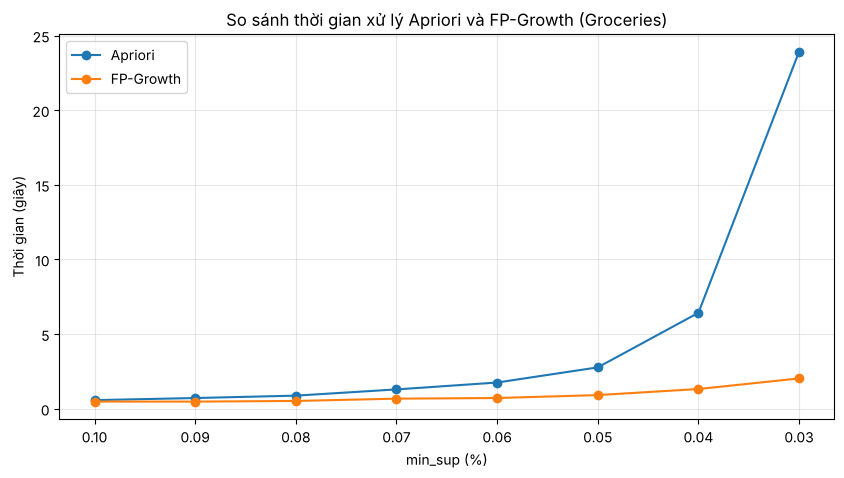

Nhận xét:
- Hai thuật toán luôn tìm ra cùng số tập phổ biến ở mọi mức min_sup.
- min_sup càng nhỏ thì số tập phổ biến càng tăng rất nhanh (13.492 tập ở 0.1% lên 166.682 tập ở 0.03%)
  và thời gian chạy của cả hai đều tăng.
- Apriori luôn chậm hơn và tăng nhanh hơn nhiều so với FP-Growth khi min_sup giảm.
Giải thích:
- Apriori phải sinh rất nhiều tập ứng viên ở mỗi mức k và duyệt lại toàn bộ dữ liệu để đếm support;
  khi min_sup nhỏ, số ứng viên bùng nổ theo cấp số nhân.
- FP-Growth chỉ duyệt dữ liệu 2 lần để nén thành cây FP, sau đó khai thác đệ quy trên các cây FP
  điều kiện mà không sinh tập ứng viên, nên nhanh hơn và ít tốn bộ nhớ hơn.


In [3]:
# ===== Câu 3 (c): Biểu đồ so sánh thời gian xử lý của Apriori và FP-Growth =====
print("Nguyễn Bình Minh - 6451071047")

result = pd.DataFrame({
    'min_sup (%)': [ms * 100 for ms in min_sups],
    'Số tập phổ biến': count_apriori,
    'Apriori (giây)': [round(t, 3) for t in time_apriori],
    'FP-Growth (giây)': [round(t, 3) for t in time_fp],
})
display(result)

plt.figure(figsize=(10, 5))
x = result['min_sup (%)']
plt.plot(x, result['Apriori (giây)'], marker='o', label='Apriori')
plt.plot(x, result['FP-Growth (giây)'], marker='o', label='FP-Growth')
plt.gca().invert_xaxis()
plt.title('So sánh thời gian xử lý Apriori và FP-Growth (Groceries)')
plt.xlabel('min_sup (%)')
plt.ylabel('Thời gian (giây)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Nhận xét:')
print('- Hai thuật toán luôn tìm ra cùng số tập phổ biến ở mọi mức min_sup.')
print('- min_sup càng nhỏ thì số tập phổ biến càng tăng rất nhanh (13.492 tập ở 0.1% lên 166.682 tập ở 0.03%)')
print('  và thời gian chạy của cả hai đều tăng.')
print('- Apriori luôn chậm hơn và tăng nhanh hơn nhiều so với FP-Growth khi min_sup giảm.')
print('Giải thích:')
print('- Apriori phải sinh rất nhiều tập ứng viên ở mỗi mức k và duyệt lại toàn bộ dữ liệu để đếm support;')
print('  khi min_sup nhỏ, số ứng viên bùng nổ theo cấp số nhân.')
print('- FP-Growth chỉ duyệt dữ liệu 2 lần để nén thành cây FP, sau đó khai thác đệ quy trên các cây FP')
print('  điều kiện mà không sinh tập ứng viên, nên nhanh hơn và ít tốn bộ nhớ hơn.')